# LeetCode #406: Queue Reconstruction by Height

https://leetcode.com/problems/queue-reconstruction-by-height/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (Try All Permutations)** | $O(n!)$ | $O(n)$ |
| **Optimal: Greedy Sort + Insert ★** | $O(n^2)$ | $O(n)$ |

---

## Understanding the Methods

### Brute Force (Try All Permutations)
Try every permutation and validate the k-constraint for each person. Entirely impractical for any non-trivial input.

### Optimal: Greedy Sort + Insert ★
Sort people by height descending (ties broken by k ascending). Then insert each person at index k in the result list. Since taller people are placed first, inserting a shorter person at position k will not affect the relative ordering of already-placed taller people.

**Why this is better than Brute Force:** The greedy insight guarantees correctness in a single pass of insertions after sorting, reducing the problem from factorial to quadratic time.

**Constraints:**
* 1 <= people.length <= 2000
* 0 <= hi <= 10^6
* 0 <= ki < people.length

## Solutions

### C#

In [ ]:
public class Solution {
    public int[][] ReconstructQueue(int[][] people) {
        Array.Sort(people, (a, b) => a[0] == b[0] ? a[1] - b[1] : b[0] - a[0]);
        var result = new List<int[]>();
        foreach (var p in people)
            result.Insert(p[1], p);
        return result.ToArray();
    }
}

### Python

In [ ]:
class Solution:
    def reconstructQueue(self, people: list[list[int]]) -> list[list[int]]:
        people.sort(key=lambda x: (-x[0], x[1]))
        result = []
        for p in people:
            result.insert(p[1], p)
        return result

### Go

In [ ]:
import "sort"

func reconstructQueue(people [][]int) [][]int {
    sort.Slice(people, func(i, j int) bool {
        if people[i][0] == people[j][0] {
            return people[i][1] < people[j][1]
        }
        return people[i][0] > people[j][0]
    })
    result := [][]int{}
    for _, p := range people {
        k := p[1]
        result = append(result, nil)
        copy(result[k+1:], result[k:])
        result[k] = p
    }
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn reconstruct_queue(mut people: Vec<Vec<i32>>) -> Vec<Vec<i32>> {
        people.sort_by(|a, b| {
            if a[0] == b[0] { a[1].cmp(&b[1]) }
            else { b[0].cmp(&a[0]) }
        });
        let mut result: Vec<Vec<i32>> = Vec::new();
        for p in people {
            let k = p[1] as usize;
            result.insert(k, p);
        }
        result
    }
}

## Example Scenarios

### 1. Common Case — Sort by Height, Insert at k
**Input:** `people = [[7,0],[4,4],[7,1],[5,0],[6,1],[5,2]]`
Sort by height **descending**, then by `k` **ascending**. Insert each person at index `k`. Because every taller (or equal) person is already placed, inserting at index `k` leaves exactly `k` people of height $\ge h$ in front — which is precisely what `k` counts. **Output:** `[[5,0],[7,0],[5,2],[6,1],[4,4],[7,1]]`

### 2. Slightly Complex — Ties in Height
**Input:** `people = [[6,0],[5,0],[6,1],[5,1],[6,2]]`
When heights tie, the smaller `k` is placed first so the larger-`k` person lands behind it, keeping both counts correct. The `k`-ascending tiebreak is what makes the insertion index always valid. **Output:** `[[5,0],[5,1],[6,0],[6,1],[6,2]]`

### 3. Edge Case: Time Factor — Strictly Decreasing Heights
**Input:** `people = [[9,0],[8,1],[7,2],[6,3]]`
All heights are distinct, so after sorting each insert at index `k` places people front-to-back and `k` equals the final position. The approach is still $O(n^2)$ because each list insertion shifts later elements. **Output:** `[[9,0],[8,1],[7,2],[6,3]]`

### 4. Edge Case: Space Factor — Single Person
**Input:** `people = [[5,0]]`
A single person is trivially their own queue — insert at index 0 of an empty list. No reordering is possible. **Output:** `[[5,0]]`

### 5. Almost-Impossible but Plausible — Everyone Wants the Front (k = 0)
**Input:** `people = [[3,0],[2,0],[1,0]]`
If every `k` is 0, sorting by height descending and then inserting each at index 0 reverses the order into ascending height. Insert `[3,0]`, then `[2,0]` at front, then `[1,0]` at front. **Output:** `[[1,0],[2,0],[3,0]]`


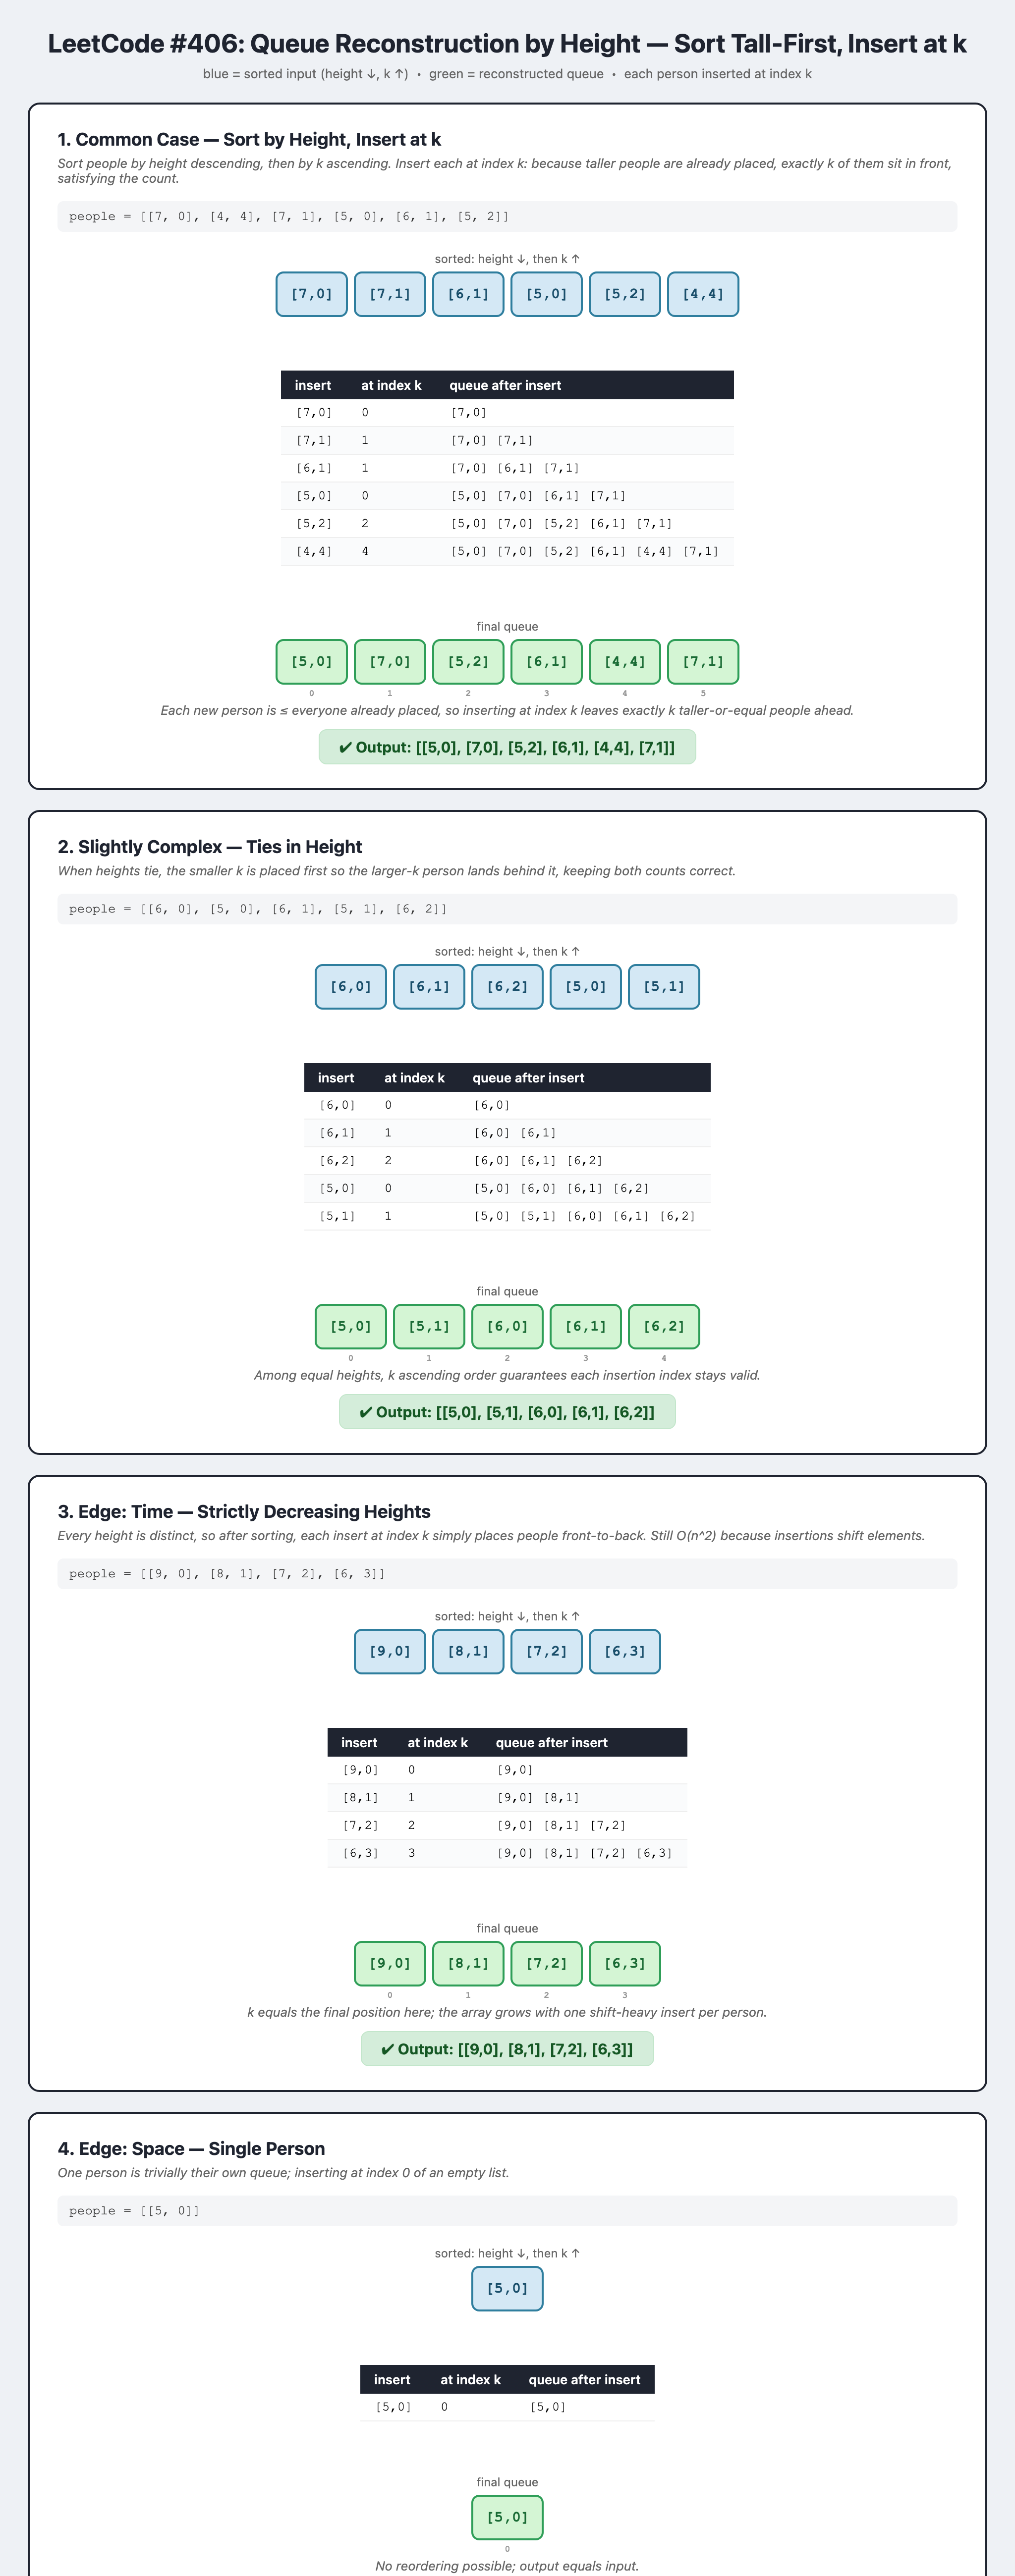